# Industry momentum and portfolio selection
George Dharma

**Do industries with stronger past returns make better portfolio holdings after
trading costs?** This project compares equal industry weights, the ten strongest
industries and a version that trades less often by retaining some existing holdings.

The core work is Python: data checks, signals, portfolio rules, cash-funded
trading costs, chronological evaluation and risk attribution. The data are
historical research portfolios, not ETF prices or a live trading record.

Use the complete project folder when rerunning this notebook. See [run instructions](../docs/RUNNING.md). All code cells below have been executed and their outputs
are saved. The first cell reproduces the original fixed experiment.

## Reading this notebook

Read from top to bottom. The sections below show the order of the analysis. Tables and charts are saved in the notebook. To recalculate, restart the Python kernel and run all cells; the first code cell runs the full experiment.

- 1  Know what one observation represents
- 2  Build a signal using past information
- 3  Separate development, selection and the final test
- 4  Ask whether the ranking predicts anything
- 5  Compare portfolio growth and losses
- 6  Finance the trades and their costs together
- 7  Separate the signal from standard equity exposures
- 8  Decision
- Sources and reproduction

[Project introduction](../README.md) · [Run instructions](../docs/RUNNING.md) · [Detailed methodology](../docs/METHODOLOGY.md)

In [1]:
from pathlib import Path
import sys

ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "equity").is_dir() and (folder / "data").is_dir()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Extract the complete project ZIP and open its notebooks folder."
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display
from equity.analysis import develop, final_test, load
from equity.engine import rebalance

pd.set_option("display.max_columns", 12)
lock, earlier_results = develop(ROOT)
print("Selection based only on 2000–2009:", lock["selected_policy"])
print(lock["validation_information_ratios"])
result = final_test(ROOT)
cfg, returns, factors, score, names = load(ROOT)
print("\nData audit")
print(json.dumps(result["audit"], indent=2))


Selection based only on 2000–2009: Top 10 momentum
{'Top 10 momentum': 0.060736937507257636, 'Buffered momentum': 0.01390846795863506}

Data audit
{
  "source_header": "This file was created using the 202609 CRSP database.",
  "first_month": "1926-07",
  "last_month": "2026-09",
  "source_months": 1203,
  "industry_count": 49,
  "study_months": 672,
  "missing_1969_2025": 6,
  "first_all_industries_month": "1969-07",
  "final_min_eligible": 49,
  "final_max_eligible": 49
}


## 1  Know what one observation represents

Each column is a US industry portfolio; each row is one month's return.
Stocks inside each industry are value weighted, so larger companies have
more influence. Our benchmark then allocates equally **across industries**.
It is therefore different from an equally weighted stock portfolio or a
market-cap-weighted equity index.

The source assigns stocks to industries using SIC industry codes at the end
of June. It also revises the historical data as the underlying database changes.
This package archives one release built from the September 2026 CRSP database.
It is not an archive of what was actually published at every past trading date.

The parser reads the first, value-weighted monthly table, converts percentages
to decimals and treats −99.99 and −999 as missing. It does not accidentally
read the later equal-weighted or annual tables. The source has 49 industries
with full return coverage from July 1969. Early signal eligibility still needs
enough past observations.

In [2]:
print("Monthly industry panel:", returns.shape)
print(
    "Eligible industries at first development month:",
    score.loc["1970-01"].notna().sum(),
)
print(
    "Eligible industries at first final-test month:", score.loc["2010-01"].notna().sum()
)
print("\nExample input rows; decimal returns")
display(returns.loc["2024-12":"2025-02", ["Gold", "Chips", "Mach"]])


Monthly industry panel: (1203, 49)
Eligible industries at first development month: 48
Eligible industries at first final-test month: 49

Example input rows; decimal returns


,Gold,Chips,Mach
2024-12,-0.1120,0.0349,-0.0884
2025-01,0.1449,-0.0597,0.0601
2025-02,-0.0141,0.0036,-0.0400


## 2  Build a signal using past information

For holding month $t$, momentum compounds the eleven monthly returns from
$t-12$ through $t-2$. The immediately preceding month, $t-1$, is skipped:

$$m_{i,t}=\prod_{j=2}^{12}(1+r_{i,t-j})-1.$$

For example, December 2025 holdings use returns from December 2024 through
October 2025. November 2025 is excluded from the score. The portfolio is
formed at the end of November and earns December's return. A complete signal
history and an observed prior-month return determine eligibility; the future
holding-month return never determines which industry is selected.

This calendar lag avoids using the holding month's outcome in the signal.
It does not establish historical publication availability for this revised
research dataset. Implementing the rule in tradable funds would require an
audited price and dividend panel with actual availability dates.

The **top-10 rule** ranks eligible industries by this signal and gives each
selected industry 10%. Ties use the industry code in alphabetical order.
The **buffered rule** retains existing holdings while their rank is 15 or better,
then fills empty places from the highest remaining ranks. It also targets ten
equal positions. Both are long only and fully invested, with no leverage.

In [3]:
sample = pd.DataFrame(result["sample"]).sort_values("rank")
display(sample[["industry", "name", "rank", "signal", "target_weight"]].head(15))
gold = sample[sample.industry == "Gold"].iloc[0]
manual_signal = np.prod(1 + gold[result["sample_months"]].to_numpy(dtype=float)) - 1
assert abs(manual_signal - gold.signal) < 1e-12
print(f"\nPrecious metals example: compounded signal = {manual_signal:.2%}")


,industry,name,rank,signal,target_weight
20,Gold,Precious Metals,1,1.037142,0.1
15,ElcEq,Electrical Equipment,2,0.407128,0.1
10,Chips,Electronic Equipment,3,0.396322,0.1
0,Aero,Aircraft,4,0.388415,0.1
22,Hardw,Computers,5,0.345015,0.1
2,Autos,Automobiles and Trucks,6,0.273256,0.1
41,Softw,Computer Software,7,0.257202,0.1
23,Hlth,Healthcare,8,0.221129,0.1
30,Mines,Non-Metallic and Industrial Metal Mining,9,0.185888,0.1
27,Mach,Machinery,10,0.180791,0.1



Precious metals example: compounded signal = 103.71%


## 3  Separate development, selection and the final test

Development covers 1970–1999. Validation covers 2000–2009 and chooses between
the two momentum rules using their net **information ratio** against the equal
industry benchmark. This ratio divides average active return by the variability
of active return; higher means more consistent relative performance.

The top-10 rule's validation ratio is 0.061, compared with 0.014 for the buffer.
That selects the top-10 rule before the 2010–2025 final test is calculated.
The program records the choice and hashes of the design and data. The final
stage refuses to run if those inputs have changed.

Each block starts in cash and pays an entry cost. Earlier observations warm
the signal but do not carry portfolio holdings into the next block. The rule
does not fit a machine-learning model; the chronological split controls
strategy selection and evaluation.

In [4]:
summary = pd.DataFrame(result["summary"])
display(
    summary[
        ["block", "policy", "cagr", "sharpe", "information_ratio", "annual_turnover"]
    ].round(4)
)


,block,policy,cagr,sharpe,information_ratio,annual_turnover
0,Development,Equal industries,0.1219,0.3740,0.0000,0.2168
1,Development,Top 10 momentum,0.1756,0.6161,0.6524,2.8364
2,Development,Buffered momentum,0.1765,0.6217,0.6703,1.6034
3,Validation,Equal industries,0.0586,0.2604,0.0000,0.3331
4,Validation,Top 10 momentum,0.0636,0.2793,0.0607,2.9252
5,Validation,Buffered momentum,0.0567,0.2438,0.0139,1.8388
6,Final test,Equal industries,0.1271,0.7409,0.0000,0.2556
7,Final test,Top 10 momentum,0.1442,0.7838,0.2493,3.0647
8,Final test,Buffered momentum,0.1576,0.8467,0.4336,1.7552


## 4  Ask whether the ranking predicts anything

The monthly **rank information coefficient**, or rank IC, is the correlation
between an industry's signal rank and its next holding-month return rank.
A positive value means stronger signals tend to precede stronger relative
returns. It measures ordering across industries, not portfolio profit.

The top-minus-bottom spread is a second diagnostic: average return of the ten
highest-ranked industries minus the ten lowest-ranked industries. It excludes
trading and stock-borrow costs and is not presented as a funded long–short
strategy. Neither statistic is the return of the long-only portfolio.

Confidence intervals use Newey–West standard errors with six monthly lags.
This allows some dependence across nearby months. The intervals remain
conditional on this dataset, rule and evaluation period.

Mean rank IC and 95% interval: 0.032562381216775904 0.0018210264213086302 0.06330373601224318
Mean monthly top-minus-bottom spread and interval: 0.0043140624999999985 -0.0012970766804099032 0.0099252016804099


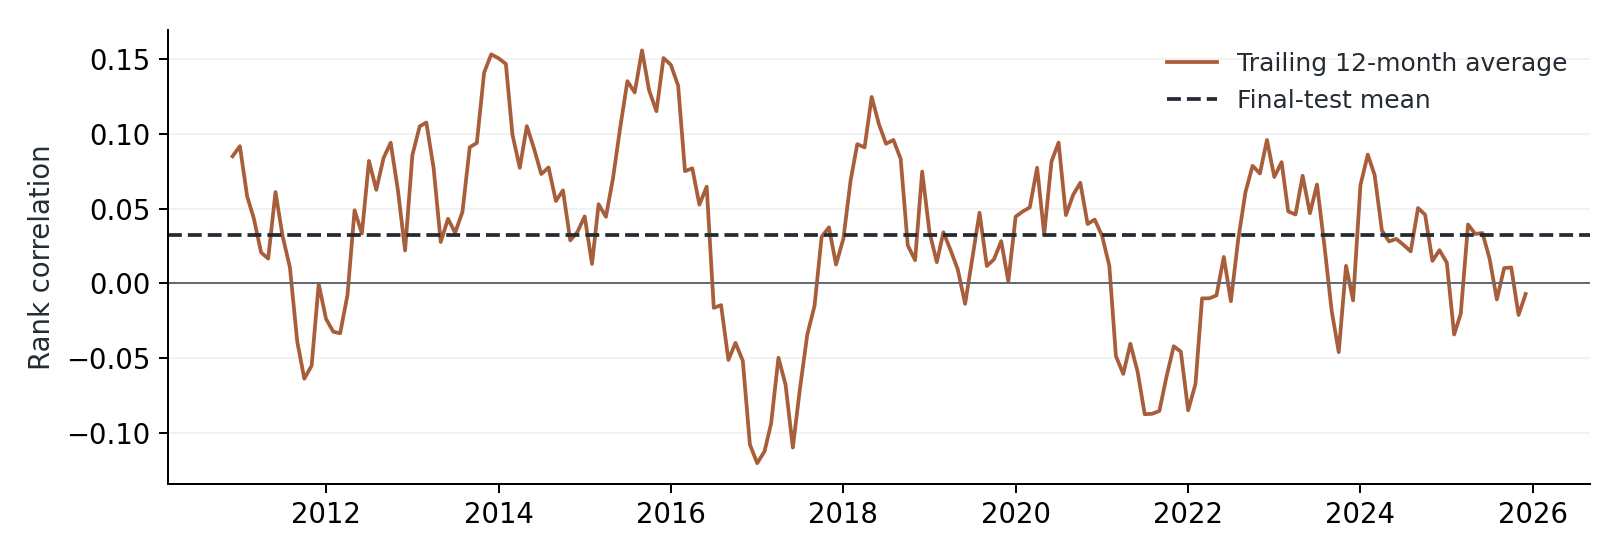

In [5]:
print(
    "Mean rank IC and 95% interval:",
    result["ic"]["coefficients"],
    result["ic"]["ci_low"],
    result["ic"]["ci_high"],
)
print(
    "Mean monthly top-minus-bottom spread and interval:",
    result["spread"]["coefficients"],
    result["spread"]["ci_low"],
    result["spread"]["ci_high"],
)
display(Image(filename=str(ROOT / "outputs/signal_quality.png")))


## 5  Compare portfolio growth and losses

Compound annual growth is the constant annual rate that would produce the
same ending wealth. Volatility describes the variation in monthly returns,
scaled to a year. The Sharpe ratio uses returns above the source's one-month
risk-free return. Maximum drawdown is the largest decline from a previous
month-end wealth peak, including the initial investment value.

The cost assumption is 10 basis points, or 0.10%, on every dollar bought or
sold. One-way turnover is the larger of total purchases and total sales,
divided by portfolio value before trading. Annual turnover adds the monthly
figures; 300% means roughly three portfolio values traded on one side over a
year. Initial entry is included.

,policy,gross_cagr,cagr,volatility,sharpe,max_drawdown,annual_turnover
6,Equal industries,0.1276,0.1271,0.1620,0.7409,-0.2595,0.2556
7,Top 10 momentum,0.1511,0.1442,0.1749,0.7838,-0.2619,3.0647
8,Buffered momentum,0.1615,0.1576,0.1763,0.8467,-0.2633,1.7552


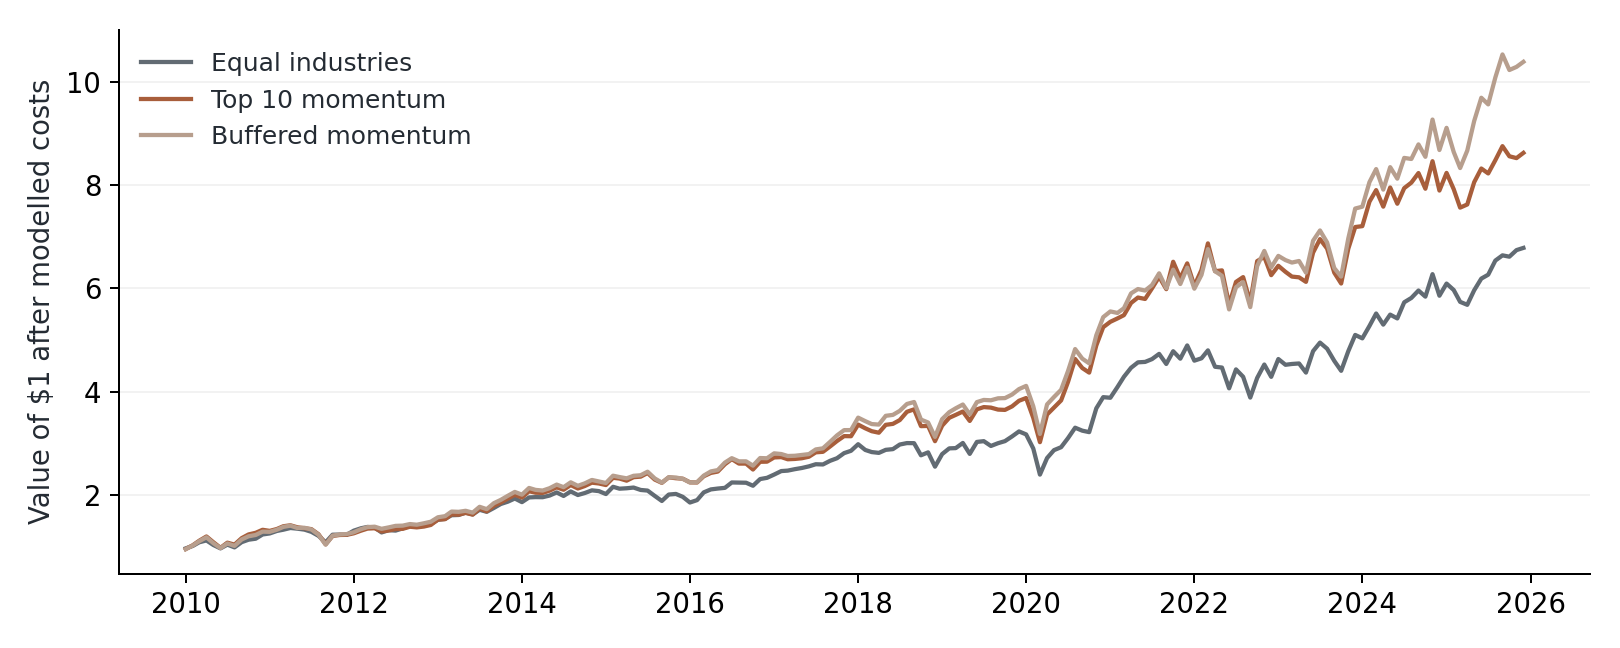

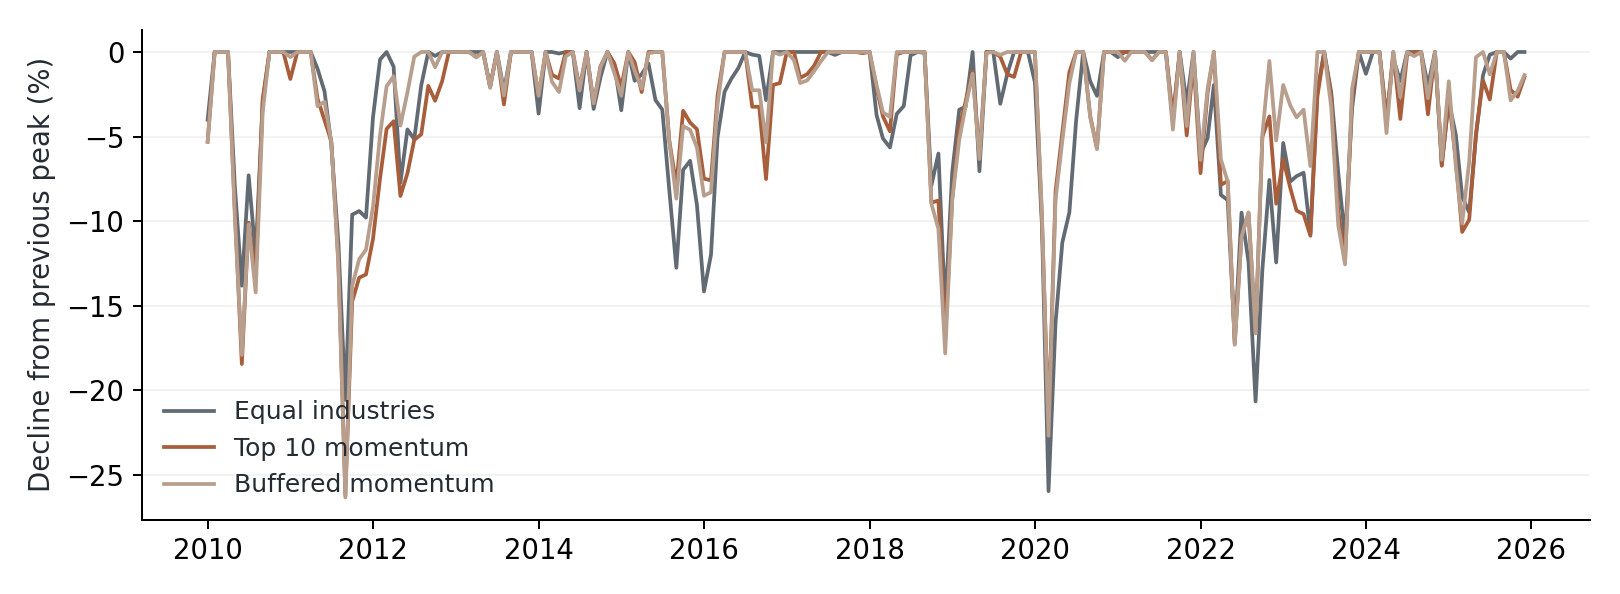

In [6]:
final = summary[summary.block == "Final test"]
display(
    final[
        [
            "policy",
            "gross_cagr",
            "cagr",
            "volatility",
            "sharpe",
            "max_drawdown",
            "annual_turnover",
        ]
    ].round(4)
)
display(Image(filename=str(ROOT / "outputs/wealth.png")))
display(Image(filename=str(ROOT / "outputs/drawdowns.png")))


## 6  Finance the trades and their costs together

Returns move the holdings away from their target weights. The next rebalance
compares the target with those **drifted** weights, rather than with last
month's old targets. Costs reduce the amount available to invest.

Let $p_i$ be pre-trade risky weights, $w_i$ target weights after costs, $c$ the
cost rate and $C$ the cost as a fraction of pre-trade wealth. The model solves

$$C=c\sum_i |(1-C)w_i-p_i|.$$

Net monthly return is $(1-C)(1+\sum_i w_i r_i)-1$. Charging cost only after
the month's return would use different timing. On initial entry, all money
starts in cash and the cost is $c/(1+c)$.

These charges represent rotation between research industry baskets. The
data do not reveal the costs of maintaining each underlying stock basket,
actual bid–ask spreads, taxes or market impact. The scenarios test cost
sensitivity; they do not estimate fund capacity.

December 2025 rebalance, per $1 of starting portfolio value
{'cost': 0.0006434591413672874, 'buys': 0.32140784111296017, 'sales': 0.3220513002543274, 'gross_traded': 0.6434591413672875, 'turnover': 0.3220513002543274}
Source gross return: 0.01254
Net return: 0.011888471880999951

Cost scenarios


policy,Buffered momentum,Equal industries,Top 10 momentum
cost_bps,,,
0,0.1615,0.1276,0.1511
10,0.1576,0.1271,0.1442
25,0.1516,0.1264,0.1338
50,0.1417,0.1251,0.1167


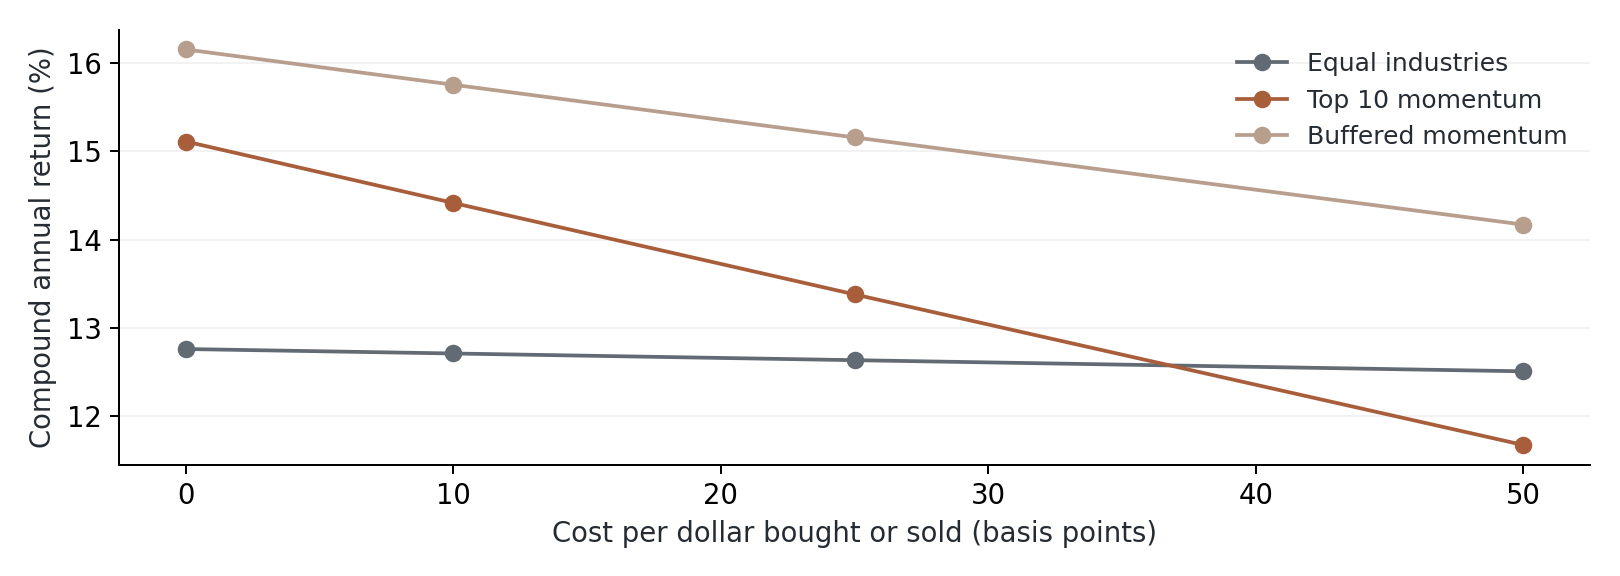

In [7]:
s = pd.DataFrame(result["sample"]).sort_values("industry")
cash = rebalance(s.target_weight, s.pretrade_weight, 10)
print("December 2025 rebalance, per $1 of starting portfolio value")
print({k: v for k, v in cash.items() if k != "trades"})
print("Source gross return:", result["sample_rebalance"]["gross_return"])
print("Net return:", result["sample_rebalance"]["net_return"])
assert abs(cash["buys"] - cash["sales"] + cash["cost"]) < 1e-12
costs = pd.DataFrame(result["costs"])
print("\nCost scenarios")
display(costs.pivot(index="cost_bps", columns="policy", values="cagr").round(4))
display(Image(filename=str(ROOT / "outputs/cost_sensitivity.png")))


## 7  Separate the signal from standard equity exposures

The regression explains monthly portfolio returns above cash using the market,
size, value and stock-momentum factors. A coefficient of 1 on the market means
about a one-percentage-point response to a one-point market-factor move,
holding the other factors fixed. This is an estimated association.

The intercept, commonly called **alpha**, is the average monthly excess return
left unexplained by those factors. Multiplying by twelve gives an arithmetic
annualised alpha, not a compound growth rate. Its confidence interval matters
because the estimate can be noisy. This analysis does not constrain or hedge
those exposures in the portfolio construction.

In [8]:
exposures = pd.DataFrame(result["factors"])
display(
    exposures[exposures.policy == lock["selected_policy"]][
        ["exposure", "coefficient", "ci_low", "ci_high"]
    ].round(5)
)
alpha = exposures[
    (exposures.policy == lock["selected_policy"])
    & (exposures.exposure == "Monthly alpha")
].iloc[0]
print(
    f"\nAnnualised alpha: {12 * alpha.coefficient:.2%}; interval {12 * alpha.ci_low:.2%} to {12 * alpha.ci_high:.2%}"
)
contribution = pd.DataFrame(result["contribution"])
print("\nLargest gross active contributions, arithmetic annual percentage points")
display(
    contribution[
        ["industry", "name", "months_held", "annual_active_contribution"]
    ].head(5)
)
print("\nSubperiods")
display(
    pd.DataFrame(result["subperiods"])
    .pivot(index="period", columns="policy", values="cagr")
    .round(4)
)
print("\nPrespecified nearby holding counts; diagnostic only")
display(
    pd.DataFrame(result["nearby"])[
        ["holdings", "cagr", "annual_turnover", "max_weight"]
    ].round(4)
)


,exposure,coefficient,ci_low,ci_high
5,Monthly alpha,-0.00070,-0.00315,0.00176
6,Market,1.08322,1.00744,1.15901
7,Size,0.28199,0.17479,0.38918
8,Value,0.18041,0.10487,0.25594
9,Stock momentum,0.35942,0.28117,0.43767



Annualised alpha: -0.84%; interval -3.78% to 2.11%

Largest gross active contributions, arithmetic annual percentage points


,industry,name,months_held,annual_active_contribution
0,Autos,Automobiles and Trucks,67,0.008583
1,Fun,Entertainment,88,0.007123
2,Txtls,Textiles,59,0.005741
3,Gold,Precious Metals,46,0.005307
4,Ships,"Shipbuilding, Railroad Equipment",63,0.004336



Subperiods


policy,Buffered momentum,Equal industries,Top 10 momentum
period,,,
2010-01 to 2014-12,0.1770,0.1567,0.1728
2015-01 to 2019-12,0.1238,0.0928,0.1149
2020-01 to 2025-12,0.1701,0.1318,0.1453



Prespecified nearby holding counts; diagnostic only


,holdings,cagr,annual_turnover,max_weight
0,8,0.1492,3.3360,0.1250
1,10,0.1442,3.0647,0.1000
2,12,0.1483,2.7289,0.0833


## 8  Decision

The selected top-10 rule grows at 14.42% per year after the assumed 10 bp
cost, compared with 12.71% for equal industries in 2010–2025. The signal's
average rank correlation is modestly positive. However, the active-return
confidence interval includes zero, and the four-factor alpha is not clearly
positive. This supports momentum as a candidate allocation rule rather than
establishing an independent source of excess return.

The buffered comparison grows at 15.76% and cuts annual turnover from about
306% to 175%. It performed better in the final sample even though validation
selected the plain rule. It remains the prespecified comparison; its final
performance does not retrospectively change the selected result. A new
selection based on that observation would need fresh evaluation data.

At 50 bp per dollar traded, the selected rule falls behind the equal-industry
benchmark. Costs and exposures therefore matter to the decision. The next
implementation step would be an audited tradable universe, with inception,
dividend and execution data, while preserving these fixed research rules.

## Sources and reproduction

- [Two Sigma public investment process](https://www.twosigma.com/businesses/investment-management/): data, modelling, portfolio construction and execution.
- [French 49 industry portfolio construction](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_49_ind_port.html) and [Data Library revisions](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html).
- [French monthly momentum factor](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_mom_factor.html): prior-month exclusion and factor definition.
- [AQR implementation research](https://www.aqr.com/insights/research/working-paper/implementing-momentum-what-have-we-learned): include turnover and costs when evaluating momentum.
- [Man AHL on overfitting](https://www.man.com/insights/overfitting-and-its-impact-on-the-investor): separate strategy selection from final evaluation.

Run `python run_analysis.py` to reproduce the fixed experiment and
`python -m unittest discover -s tests -v` for the 21 financial and timing tests.
The README maps each exhibit to its exported table. The report and Excel
companion use these same results. The Excel sample signal, trade-cost solver,
wealth paths and drawdowns recalculate; the full backtest and statistical
inference are Python outputs.